# 05: Predict celltypes

In [51]:
import seaborn as sns
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
import scanpy as sc
import anndata as ad
import pandas as pd
import math

## Get data

In [52]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")

In [53]:
adata_both = ad.read_h5ad(data_dir / Path("adata_both_modalities_for_training.h5ad"))
adata_gexp = adata_both[:, adata_both.var["feat_type"] == "gexp"].copy()
adata_morph = adata_both[:, adata_both.var["feat_type"] == "morphology"].copy()

In [66]:
adata_gexp

AnnData object with n_obs × n_vars = 87552 × 181
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px', 'leiden', 'celltypes_coarse_base', 'celltypes_coarse_medium', 'celltypes_coarse_very'
    var: 'feat_type'

## Train XGB classifier

In [54]:
random_state = 42
label_to_predict = "celltypes_coarse_very"

# shared model params
objective = "multi:softprob"       # multiclass classification
eval_metric = "mlogloss"           # evaluation metric
n_estimators = 100                 # number of boosting rounds
max_depth = 6                      # maximum tree depth
learning_rate = 0.1                # learning rate

# shared data split params
test_size = 0.1

### Gene expression only

In [71]:
# set up data

gexp_X_train = adata_gexp[adata_gexp.obs["tissue"] == "Half"].to_df()
gexp_y_train_raw = adata_gexp[adata_gexp.obs["tissue"] == "Half"].obs[label_to_predict].values
gexp_X_test = adata_gexp[adata_gexp.obs["tissue"] == "Quarter"].to_df()
gexp_y_test_raw = adata_gexp[adata_gexp.obs["tissue"] == "Quarter"].obs[label_to_predict].values

label_encoder = LabelEncoder()
gexp_y_train = label_encoder.fit_transform(gexp_y_train_raw)
gexp_y_test = label_encoder.transform(gexp_y_test_raw)

gexp_X_train_sub, gexp_X_val, gexp_y_train_sub, gexp_y_val = train_test_split(
    gexp_X_train,
    gexp_y_train,
    test_size=test_size,
    random_state=random_state,
    stratify=gexp_y_train
)

In [72]:
gexp_model = XGBClassifier(
    objective=objective,
    eval_metric=eval_metric,
    n_estimators=n_estimators,
    max_depth=max_depth,
    learning_rate=learning_rate,
    random_state=random_state
)

In [73]:
gexp_model.fit(
    gexp_X_train_sub,
    gexp_y_train_sub,
    eval_set=[(gexp_X_val, gexp_y_val)],
    verbose=False
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

### Morphology only

In [58]:
# set up data

morph_X_train = adata_morph[adata_morph.obs["tissue"] == "Half"].to_df()
morph_y_train_raw = adata_morph[adata_morph.obs["tissue"] == "Half"].obs[label_to_predict].values
morph_X_test = adata_morph[adata_morph.obs["tissue"] == "Quarter"].to_df()
morph_y_test_raw = adata_morph[adata_morph.obs["tissue"] == "Quarter"].obs[label_to_predict].values

label_encoder = LabelEncoder()
morph_y_train = label_encoder.fit_transform(morph_y_train_raw)
morph_y_test = label_encoder.transform(morph_y_test_raw)

morph_X_train_sub, morph_X_val, morph_y_train_sub, morph_y_val = train_test_split(
    morph_X_train,
    morph_y_train,
    test_size=test_size,
    random_state=random_state,
    stratify=morph_y_train
)

In [59]:
morph_model = XGBClassifier(
    objective=objective,
    eval_metric=eval_metric,
    n_estimators=n_estimators,
    max_depth=max_depth,
    learning_rate=learning_rate,
    random_state=random_state
)

In [60]:
morph_model.fit(
    morph_X_train_sub,
    morph_y_train_sub,
    eval_set=[(morph_X_val, morph_y_val)],
    verbose=False
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

### Both modalities

In [61]:
# set up data

both_X_train = adata_both[adata_both.obs["tissue"] == "Half"].to_df()
both_y_train_raw = adata_both[adata_both.obs["tissue"] == "Half"].obs[label_to_predict].values
both_X_test = adata_both[adata_both.obs["tissue"] == "Quarter"].to_df()
both_y_test_raw = adata_both[adata_both.obs["tissue"] == "Quarter"].obs[label_to_predict].values

label_encoder = LabelEncoder()
both_y_train = label_encoder.fit_transform(both_y_train_raw)
both_y_test = label_encoder.transform(both_y_test_raw)

both_X_train_sub, both_X_val, both_y_train_sub, both_y_val = train_test_split(
    both_X_train,
    both_y_train,
    test_size=test_size,
    random_state=random_state,
    stratify=both_y_train
)

In [62]:
both_model = XGBClassifier(
    objective=objective,
    eval_metric=eval_metric,
    n_estimators=n_estimators,
    max_depth=max_depth,
    learning_rate=learning_rate,
    random_state=random_state
)

In [63]:
both_model.fit(
    both_X_train_sub,
    both_y_train_sub,
    eval_set=[(both_X_val, both_y_val)],
    verbose=False
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

### Aggregate model evals

In [74]:
# gexp

gexp_seen = np.unique(gexp_y_test)
gexp_seen_names = [str(label_encoder.classes_[i]) for i in gexp_seen]
gexp_y_pred = gexp_model.predict(gexp_X_test)

gexp_report = classification_report(
    gexp_y_test,
    gexp_y_pred,
    labels=gexp_seen,
    target_names=gexp_seen_names,
    output_dict=True,
    zero_division=0
)
gexp_report_df = pd.DataFrame(gexp_report).T
gexp_report_df

,precision,recall,f1-score,support
Epithelial cells,0.982059,0.924376,0.952345,1362.000000
Glia,0.944741,0.939281,0.942003,12632.000000
Immune cells,0.920363,0.931633,0.925963,980.000000
Neural progenitor cells,0.920000,0.294118,0.445736,391.000000
Neurons,0.960004,0.987214,0.973419,19475.000000
Vascular cells,0.943215,0.908111,0.925330,3896.000000
accuracy,0.953015,0.953015,0.953015,0.953015
macro avg,0.945064,0.830789,0.860800,38736.000000
weighted avg,0.952707,0.953015,0.951069,38736.000000


In [67]:
# morph

morph_seen = np.unique(morph_y_test)
morph_seen_names = [str(label_encoder.classes_[i]) for i in morph_seen]
morph_y_pred = morph_model.predict(morph_X_test)

morph_report = classification_report(
    morph_y_test,
    morph_y_pred,
    labels=morph_seen,
    target_names=morph_seen_names,
    output_dict=True,
    zero_division=0
)
morph_report_df = pd.DataFrame(morph_report).T
morph_report_df

,precision,recall,f1-score,support
Epithelial cells,0.000000,0.000000,0.000000,1362.000000
Glia,0.267029,0.625633,0.374301,12632.000000
Immune cells,0.000000,0.000000,0.000000,980.000000
Neural progenitor cells,0.000000,0.000000,0.000000,391.000000
Neurons,0.212105,0.080616,0.116829,19475.000000
Vascular cells,0.460622,0.178645,0.257444,3896.000000
accuracy,0.262521,0.262521,0.262521,0.262521
macro avg,0.156626,0.147482,0.124762,38736.000000
weighted avg,0.240046,0.262521,0.206692,38736.000000


In [68]:
# both

both_seen = np.unique(both_y_test)
both_seen_names = [str(label_encoder.classes_[i]) for i in both_seen]
both_y_pred = both_model.predict(both_X_test)

both_report = classification_report(
    both_y_test,
    both_y_pred,
    labels=both_seen,
    target_names=both_seen_names,
    output_dict=True,
    zero_division=0
)
both_report_df = pd.DataFrame(both_report).T
both_report_df

,precision,recall,f1-score,support
Epithelial cells,0.982759,0.878855,0.927907,1362.000000
Glia,0.937276,0.930969,0.934112,12632.000000
Immune cells,0.917505,0.930612,0.924012,980.000000
Neural progenitor cells,0.010000,0.002558,0.004073,391.000000
Neurons,0.950354,0.986855,0.968260,19475.000000
Vascular cells,0.937603,0.879363,0.907550,3896.000000
accuracy,0.942663,0.942663,0.942663,0.942663
macro avg,0.789249,0.768202,0.777652,38736.000000
weighted avg,0.935623,0.942663,0.938747,38736.000000


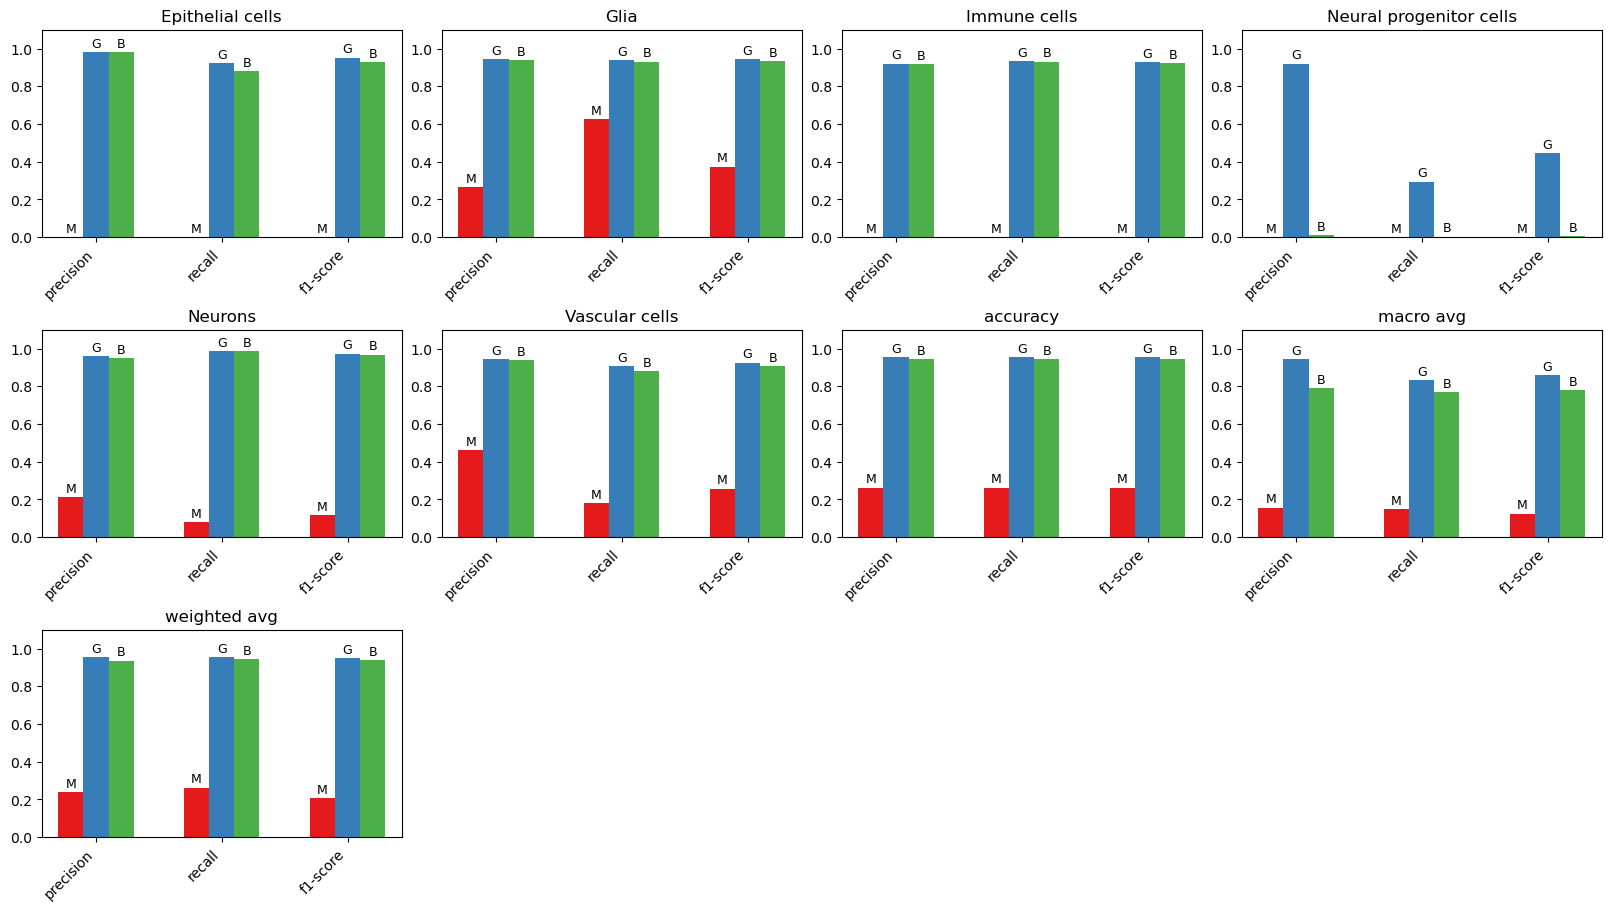

In [75]:
dfs = [morph_report_df, gexp_report_df, both_report_df]
model_names = ["morph", "gexp", "both"]
colors = ["#e41a1c", "#377eb8", "#4daf4a"]
letters = ["M", "G", "B"]  # one letter per dataframe, in the same order

metrics = ["precision", "recall", "f1-score"]
n = len(dfs[0])
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows=nrows, ncols=ncols,
    figsize=(ncols * 4, nrows * 3),
    constrained_layout=True
)
axes = axes.flatten()

for i, class_name in enumerate(dfs[0].index):
    ax = axes[i]
    x = list(range(len(metrics)))
    width = 0.2

    for j, (df, name, color, letter) in enumerate(zip(dfs, model_names, colors, letters)):
        positions = [xi + (j - 1) * width for xi in x]
        vals = df.loc[class_name, metrics].values
        bars = ax.bar(positions, vals, width=width,
                      label=name if i == 0 else "", color=color)

        # annotate each bar with its letter
        for pos, val in zip(positions, vals):
            ax.text(
                pos,
                val + 0.01,       # small offset above the bar
                letter,
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.set_ylim(0, 1.1)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, rotation=45, ha="right")
    ax.set_title(class_name)

# remove any empty subplots
for ax in axes[n:]:
    fig.delaxes(ax)

plt.show()

## Train MLP

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# --- Dataset & Model ---
class CellDataset(Dataset):
    def __init__(self, features: np.ndarray, labels: np.ndarray):
        self.X = torch.tensor(features, dtype=torch.float32)
        self.y = torch.tensor(labels, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class SimpleMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims=[512,256], num_classes=10, dropout_p=0.5):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers += [
                nn.Linear(prev, h),
                nn.BatchNorm1d(h),
                nn.ReLU(inplace=True),
                nn.Dropout(dropout_p)
            ]
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

# --- Data prep helper ---
def prepare_dataloaders(
    adata, 
    tissue_train="Half", 
    tissue_test="Quarter", 
    label_key=label_to_predict,
    test_size=0.2,
    random_state=0,
    batch_size_train=128,
    batch_size_eval=256
):
    # train vs test by tissue
    X_train_df = adata[adata.obs["tissue"] == tissue_train].to_df()
    y_train_raw = adata[adata.obs["tissue"] == tissue_train].obs[label_key].values
    X_test_df  = adata[adata.obs["tissue"] == tissue_test].to_df()
    y_test_raw = adata[adata.obs["tissue"] == tissue_test].obs[label_key].values

    # encode labels
    le = LabelEncoder()
    y_train = le.fit_transform(y_train_raw)
    y_test  = le.transform(y_test_raw)

    # split train→ train_sub + val
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_df.values, y_train,
        test_size=test_size,
        random_state=random_state,
        stratify=y_train
    )

    # build datasets & loaders
    train_loader = DataLoader(CellDataset(X_tr, y_tr),
                              batch_size=batch_size_train, shuffle=True, num_workers=4)
    val_loader   = DataLoader(CellDataset(X_val, y_val),
                              batch_size=batch_size_eval, shuffle=False, num_workers=4)
    test_loader  = DataLoader(CellDataset(X_test_df.values, y_test),
                              batch_size=batch_size_eval, shuffle=False, num_workers=4)

    input_dim   = X_tr.shape[1]
    num_classes = len(le.classes_)

    return train_loader, val_loader, test_loader, input_dim, num_classes, le

# --- Train & Eval helpers ---
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.
    for Xb, yb in loader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(Xb), yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * Xb.size(0)
    return total_loss / len(loader.dataset)

def evaluate(model, loader, device):
    model.eval()
    correct = 0
    with torch.no_grad():
        for Xb, yb in loader:
            Xb, yb = Xb.to(device), yb.to(device)
            preds = model(Xb).argmax(dim=1)
            correct += (preds == yb).sum().item()
    return correct / len(loader.dataset)

def run_training(
    adata, 
    scenario_name: str,
    tissue_train="Half",
    tissue_test="Quarter",
    label_key="coarse_cell_type",
    test_size=0.2,
    random_state=0,
    epochs=20,
    lr=1e-3,
    hidden_dims=[1024,512],
    dropout_p=0.3,
    device="cuda"
):
    print(f"\n=== Scenario: {scenario_name} ===")
    (train_loader, val_loader, test_loader,
     input_dim, num_classes, le) = prepare_dataloaders(
         adata,
         tissue_train, tissue_test, label_key,
         test_size, random_state
    )

    model = SimpleMLP(
        input_dim=input_dim,
        hidden_dims=hidden_dims,
        num_classes=num_classes,
        dropout_p=dropout_p
    ).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # training loop
    for ep in range(1, epochs+1):
        tr_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_acc = evaluate(model, val_loader, device)
        print(f"Ep {ep:02d} — Train loss {tr_loss:.4f} — Val acc {val_acc:.4f}")

    test_acc = evaluate(model, test_loader, device)
    print(f"→ Test accuracy: {test_acc:.4f}  (labels: {le.classes_})")

    return model, le


In [ ]:
scenarios = {
    "gene only":   adata_gexp,
    "morph only":  adata_morph,
    "gene+morph":  adata_both
}
results = {}
for name, ad in scenarios.items():
    mdl, le = run_training(
        adata=ad,
        scenario_name=name,
        test_size=0.2,
        random_state=42,
        epochs=30,
        lr=1e-3,
        hidden_dims=[1024, 512],
        dropout_p=0.3,
        device="cuda"
    )
    results[name] = (mdl, le)


=== Scenario: gene only ===
Ep 01 — Train loss 0.5235 — Val acc 0.8778
Ep 02 — Train loss 0.3613 — Val acc 0.8841
Ep 03 — Train loss 0.3303 — Val acc 0.8891
Ep 04 — Train loss 0.3011 — Val acc 0.8859
Ep 05 — Train loss 0.2845 — Val acc 0.8861
Ep 06 — Train loss 0.2693 — Val acc 0.8831
Ep 07 — Train loss 0.2495 — Val acc 0.8886
Ep 08 — Train loss 0.2361 — Val acc 0.8841
Ep 09 — Train loss 0.2285 — Val acc 0.8894
Ep 10 — Train loss 0.2127 — Val acc 0.8833
Ep 11 — Train loss 0.2015 — Val acc 0.8879
Ep 12 — Train loss 0.1905 — Val acc 0.8850
Ep 13 — Train loss 0.1837 — Val acc 0.8846
Ep 14 — Train loss 0.1672 — Val acc 0.8870
Ep 15 — Train loss 0.1631 — Val acc 0.8883
Ep 16 — Train loss 0.1571 — Val acc 0.8890
Ep 17 — Train loss 0.1469 — Val acc 0.8876
Ep 18 — Train loss 0.1401 — Val acc 0.8817
Ep 19 — Train loss 0.1427 — Val acc 0.8846
Ep 20 — Train loss 0.1245 — Val acc 0.8837
Ep 21 — Train loss 0.1235 — Val acc 0.8869
Ep 22 — Train loss 0.1174 — Val acc 0.8851
Ep 23 — Train loss 0.1195

## Visualise results

<Axes: >

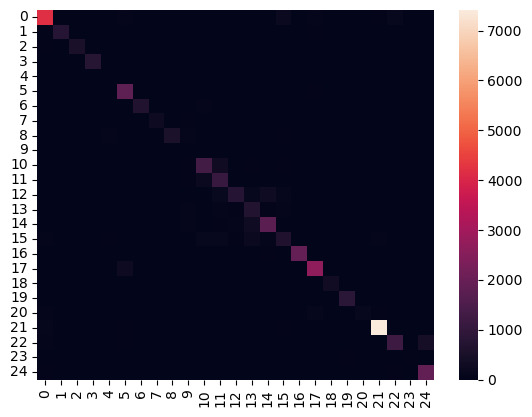

In [ ]:
sns.heatmap(confusion_matrix(y_test, y_pred))

In [ ]:
celltypes = [r for r in gexp_report_df.index if r not in ("accuracy", "micro avg", "macro avg", "weighted avg")]
f1_scores = gexp_report_df.loc[celltypes, "f1-score"].tolist()

# --- 2) grab your hex‐color dict from adata ---
cats    = adata_both_hvgs.obs["coarse_cell_type"].cat.categories.tolist()
hexes   = adata_both_hvgs.uns["coarse_cell_type_colors"]
color_dict = dict(zip(cats, hexes))

In [ ]:
sdata_half.tables["gexp"].obs["coarse_cell_type"] = pd.Categorical(adata_both_hvgs.obs.query("tissue == 'Half'")["coarse_cell_type"])

In [ ]:
def plot_f1_violin(ax):
    """
    On the passed‐in Axes `ax`, draws:
      – grey violins for two scenarios (“Gene Expression” vs “Gene + Morphology”)
      – colored connector‐lines per cell‐type
      – hollow circles per cell‐type, colored by your adata palette.
    Assumes the following are defined in the global scope:
      celltypes, f1_expr, f1_expr_morph, adata_both_hvgs
    """
    # --- 1) build the long DataFrame ---
    df = pd.DataFrame({
        "CellType":   celltypes * 2,
        "F1":          f1_scores + f1_scores,
        "Scenario":   ["Gene Expression"] * len(celltypes)
                     + ["Gene + Morphology"] * len(celltypes)
    })

    # --- 3) the grey violins ---
    # sns.violinplot(
    #     x="Scenario", y="F1", data=df,
    #     inner=None,            # no quartiles
    #     color="lightgrey",
    #     ax=ax
    #)

    # --- 4) colored connector lines ---
    for ct in celltypes:
        y0 = df.loc[(df.CellType==ct)&(df.Scenario=="Gene Expression"),    "F1"].item()
        y1 = df.loc[(df.CellType==ct)&(df.Scenario=="Gene + Morphology"), "F1"].item()
        ax.plot([0,1], [y0,y1],
                color=color_dict[ct],
                alpha=0.7,
                linewidth=3)

    # --- 5) hollow circles, colored by cell‐type ---
    sns.stripplot(
        x="Scenario", y="F1", data=df,
        hue="CellType",
        palette=color_dict,
        size=12,
        jitter=False,
        edgecolor="black",
        linewidth=0,
        ax=ax
    )
    ax.get_legend().remove()   # we’ll build the legend elsewhere
    ax.set_ylabel("F1 Score")

    # for spine in ["top", "right", "bottom"]:
    #     ax.spines[spine].set_visible(False)

    # remove the x‐axis ticks and label
    ax.set_xticks([])
    ax.set_xlabel("")

    return ax


In [ ]:
from matplotlib.lines import Line2D

def create_celltype_legend(ax, color_dict, ncol=2, title="Cell Types"):
    """
    On the passed‐in Axes `ax`, draws a legend of cell‐type circles.
    
    Parameters
    ----------
    ax : matplotlib.axes.Axes
        The axes to draw the legend into.
    color_dict : dict
        Mapping from cell‐type name to hex color.
    ncol : int, optional
        Number of columns in the legend. Default is 2.
    title : str, optional
        Legend title. Default is "Cell Types".
    """
    # build one Line2D per cell‐type, with circular markers
    handles = [
        Line2D(
            [0], [0],
            marker="o",
            color="none",
            markerfacecolor=color,
            markeredgecolor="black",
            markersize=8,
            label=ct
        )
        for ct, color in color_dict.items()
    ]
    ax.legend(
        handles=handles,
        title=title,
        loc="center",
        ncol=ncol,
        frameon=False
    )
    ax.axis("off")
    return ax

In [ ]:
del sdata_half.tables["gexp"].uns["coarse_cell_type_colors"]

KeyError: 'coarse_cell_type_colors'

In [ ]:
crop = sdata_half.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[10450, 10300],
    max_coordinate=[10850, 10700],
    target_coordinate_system="global",
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:798: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


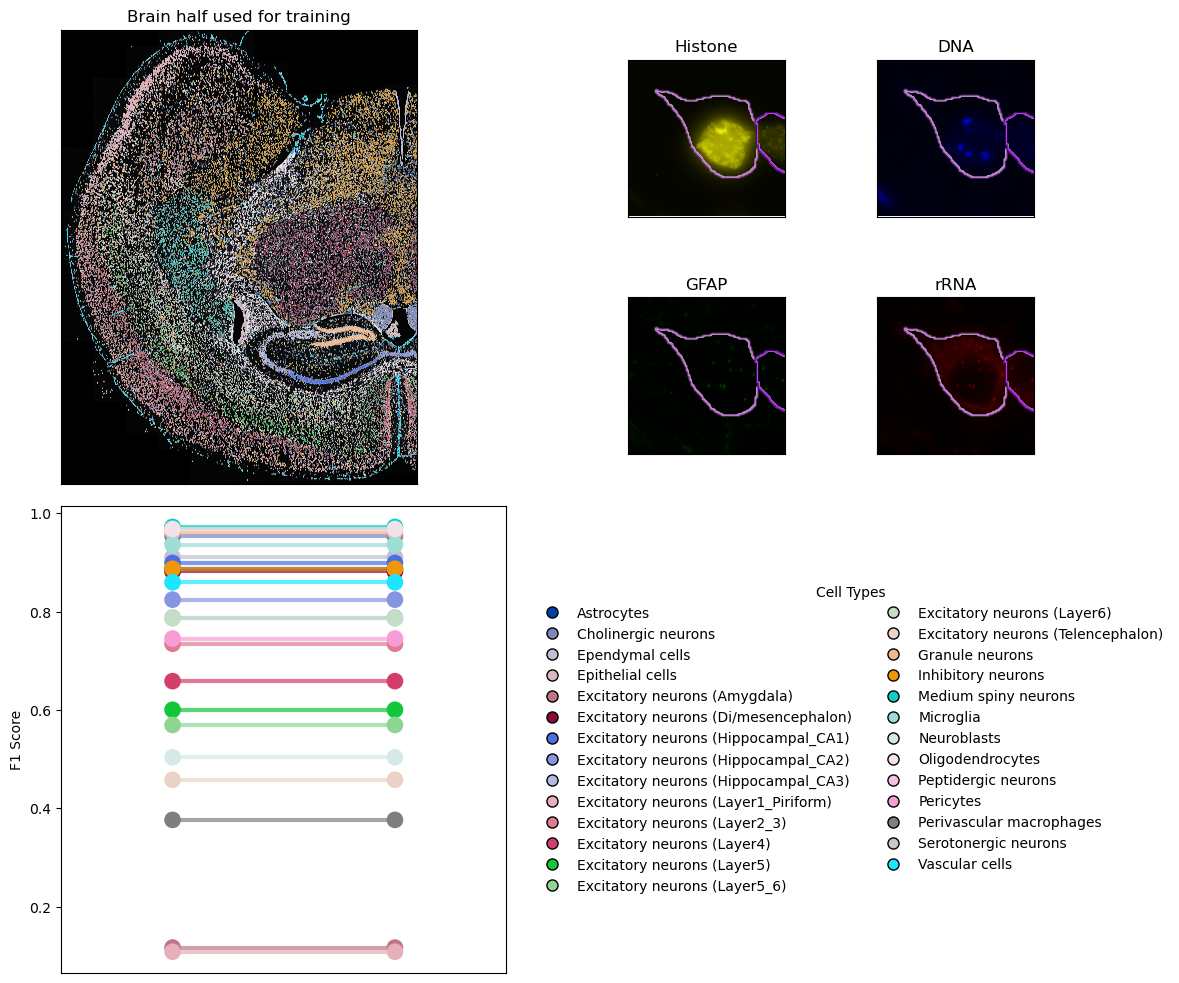

In [ ]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(12,10))

# 1) Make an “outer” 2×2 GridSpec
outer_gs = GridSpec(2, 2, figure=fig)

# ── Top-Left: Brain ────────────────────────────────────────────
ax_brain = fig.add_subplot(outer_gs[0, 0])
(
    sdata_half
    .pl.render_images(channel="DNA", scale="scale2", cmap="gray")
    .pl.render_labels(scale="scale2", color="coarse_cell_type", fill_alpha=1)
    .pl.show(ax=ax_brain, title="Brain half used for training")
)

ax_brain.set_xticks([])
ax_brain.set_yticks([])
# clear any axis labels/titles
ax_brain.set_xlabel("")
ax_brain.set_ylabel("")

# remove the Scanpy legend on that axis
leg = ax_brain.get_legend()
if leg:
    leg.remove()

# ── Bottom-Left: Violin + Lines ────────────────────────────────
ax_violin = fig.add_subplot(outer_gs[1, 0])
plot_f1_violin(ax_violin)

# ── Top-Right: subdivide into 2×2 ──────────────────────────────
inner_gs = outer_gs[0, 1].subgridspec(2, 2)

ax00 = fig.add_subplot(inner_gs[0, 0])
ax01 = fig.add_subplot(inner_gs[0, 1])
ax10 = fig.add_subplot(inner_gs[1, 0])
ax11 = fig.add_subplot(inner_gs[1, 1])

(
    crop
    .pl.render_images(channel="Histone", scale="scale0", palette="yellow")
    .pl.render_labels(fill_alpha=0, outline_alpha=1, contour_px=10)
    .pl.show(ax=ax00, title="Histone")
)

(
    crop
    .pl.render_images(channel="DNA", scale="scale0", palette="blue")
    .pl.render_labels(fill_alpha=0, outline_alpha=1, contour_px=10)
    .pl.show(ax=ax01, title="DNA")
)

(
    crop
    .pl.render_images(channel="GFAP", scale="scale0", palette="green")
    .pl.render_labels(fill_alpha=0, outline_alpha=1, contour_px=10)
    .pl.show(ax=ax10, title="GFAP")
)

(
    crop
    .pl.render_images(channel="rRNA", scale="scale0", palette="red")
    .pl.render_labels(fill_alpha=0, outline_alpha=1, contour_px=10)
    .pl.show(ax=ax11, title="rRNA")
)

for ax in (ax00, ax01, ax10, ax11):
    # completely remove tick marks
    ax.set_xticks([])
    ax.set_yticks([])
    # clear any axis labels/titles
    ax.set_xlabel("")
    ax.set_ylabel("")

# put your circle-legend in the upper-left of that block
ax_legend = fig.add_subplot(outer_gs[1, 1])
create_celltype_legend(ax_legend, color_dict, ncol=2)

# turn the other three small panels off
# for ax in (ax01, ax10, ax11):
#     ax.axis("off")

# ── Bottom-Right: unused ───────────────────────────────────────
# ax_blank.axis("off")

# ── Finally: delete ANY extra colorbar axes Scanpy snuck in ─────
keep = {ax_brain, ax_violin, ax_legend, ax00, ax01, ax10, ax11}
for ax in fig.axes[:]:
    if ax not in keep:
        fig.delaxes(ax)

plt.tight_layout()
plt.show()


In [ ]:
crop

SpatialData object
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 400, 400), (5, 200, 200), (5, 100, 100), (5, 50, 50), (5, 25, 25)
├── Labels
│     └── 'segmentation': DataTree[yx] (400, 400), (200, 200), (100, 100), (50, 50), (25, 25)
├── Points
│     └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
└── Tables
      └── 'gexp': AnnData (3, 960)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), segmentation (Labels), points (Points)

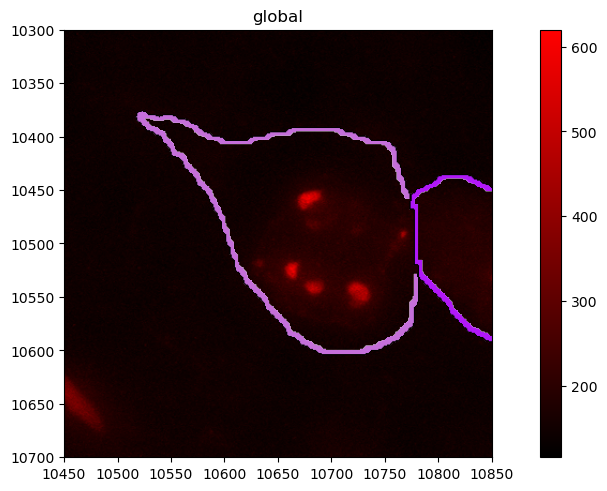

In [ ]:
(
    crop
    .pl.render_images(channel="DNA", scale="scale0", palette="red")
    .pl.render_labels(fill_alpha=0, outline_alpha=1, contour_px=10)
    .pl.show()
)
#ValueError: Invalid channel(s): DNA2. Valid choices are: ['Histone' 'DNA' 'GFAP' 'G' 'rRNA']